# Q3: Autoencoders on CIFAR-10

In [1]:
from pathlib import Path
import random
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from torchvision import datasets, transforms
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import SGDClassifier
from IPython.display import display
import joblib

SEED = 26001
DATA_FOLDER = Path("data")
RESULTS = Path("results_q3")
RESULTS.mkdir(exist_ok=True)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", DEVICE)
print("Seed:", SEED)
print("PyTorch:", torch.__version__)

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(SEED)

Device: cpu
Seed: 26001
PyTorch: 2.15.0+cpu


## Common setup for Q3

We reuse the Q1 split and the clean CNN selected by validation loss in Q2. Images for the autoencoders use pixel values in [0, 1]. The Q2 CNN remains fixed during Q3.

In [2]:
cnn_path = Path("results_q2/CNN_clean_best.pt")
if not cnn_path.exists():
    raise FileNotFoundError(
        "Q2 clean CNN checkpoint not found. Put this notebook in the same folder as Q2 "
        "and complete the Q2 training cell first: expected results_q2/CNN_clean_best.pt"
    )
print("Q2 CNN checkpoint found:", cnn_path)

# The autoencoders work directly with pixel values in [0, 1].
train_data = datasets.CIFAR10(root=str(DATA_FOLDER), train=True,
                              download=True, transform=transforms.ToTensor())
labels = np.array(train_data.targets)
train_indices, val_indices = train_test_split(
    np.arange(len(train_data)), train_size=45000, test_size=5000,
    random_state=SEED, stratify=labels
)

q1_split_path = Path("results/split_seed_26001.npz")
if q1_split_path.exists():
    with np.load(q1_split_path) as old_split:
        assert np.array_equal(train_indices, old_split["train_indices"]), "Training split differs from Q1."
        assert np.array_equal(val_indices, old_split["val_indices"]), "Validation split differs from Q1."
    print("Split matches Q1.")
else:
    print("Q1 split file not found here; recreated the split with the same seed and method.")
np.savez(RESULTS / "split_seed_26001.npz", train_indices=train_indices,
         val_indices=val_indices, seed=SEED)
print("Training images:", len(train_indices), "| Validation images:", len(val_indices))

Q2 CNN checkpoint found: results_q2\CNN_clean_best.pt
Split matches Q1.
Training images: 45000 | Validation images: 5000


## Q3(b). Corruption setup

Add Gaussian noise with standard deviation 0.20 to each image and clip pixel values to [0, 1]. The noise is reproducible for each image. The denoising autoencoder takes the noisy image as input and learns to reconstruct its corresponding clean image without using class labels.

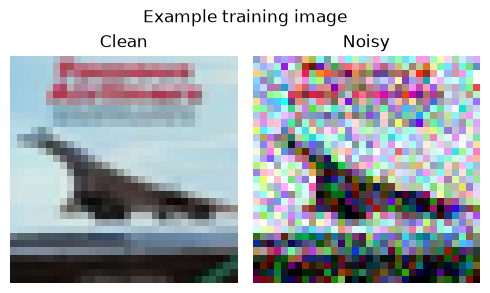

In [3]:
NOISE_STD = 0.20
BATCH_SIZE = 128
EPOCHS = 20
LEARNING_RATE = 0.001
BOTTLENECKS = [32, 128, 512]

class ImagePairs(Dataset):
    def __init__(self, base_data, indices, test_data=False):
        self.base_data = base_data
        self.indices = indices
        self.test_data = test_data

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, item):
        index = int(self.indices[item])
        clean, label = self.base_data[index]
        # The test offset keeps the train and test noise seeds separate.
        noise_seed = SEED + index + (1000000 if self.test_data else 0)
        generator = torch.Generator().manual_seed(noise_seed)
        noise = torch.randn(clean.shape, generator=generator) * NOISE_STD
        noisy = (clean + noise).clamp(0.0, 1.0)
        return clean, noisy, label

def make_loader(dataset, shuffle=False):
    generator = torch.Generator().manual_seed(SEED)
    return DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=shuffle,
                      num_workers=0, pin_memory=(DEVICE.type == "cuda"),
                      generator=generator)

train_set = ImagePairs(train_data, train_indices)
val_set = ImagePairs(train_data, val_indices)
train_loader = make_loader(train_set, shuffle=True)
train_feature_loader = make_loader(train_set)
val_loader = make_loader(val_set)

clean, noisy, label = train_set[0]
fig, axes = plt.subplots(1, 2, figsize=(5, 3))
for ax, image, title in zip(axes, [clean, noisy], ["Clean", "Noisy"]):
    ax.imshow(image.permute(1, 2, 0))
    ax.set_title(title)
    ax.axis("off")
fig.suptitle("Example training image")
fig.tight_layout()
fig.savefig(RESULTS / "example_noise.png", dpi=160)
plt.show()

## Q3(a). Compare three convolutional autoencoders

The autoencoders have bottleneck sizes **32, 128, and 512**. Apart from the bottleneck and the connected layers needed to change its size, the convolutional architecture and training settings are the same. We compare validation mean squared error (MSE) and choose the lowest-MSE model before inspecting the test results.

In [4]:
class ConvAutoencoder(nn.Module):
    def __init__(self, bottleneck_size):
        super().__init__()
        self.encoder_conv = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=4, stride=2, padding=1), nn.ReLU(),
            nn.Conv2d(32, 64, kernel_size=4, stride=2, padding=1), nn.ReLU(),
            nn.Conv2d(64, 64, kernel_size=4, stride=2, padding=1), nn.ReLU(),
            nn.Flatten()
        )
        self.to_bottleneck = nn.Sequential(nn.Linear(64 * 4 * 4, bottleneck_size), nn.ReLU())
        self.from_bottleneck = nn.Sequential(nn.Linear(bottleneck_size, 64 * 4 * 4), nn.ReLU())
        self.decoder_conv = nn.Sequential(
            nn.ConvTranspose2d(64, 64, kernel_size=4, stride=2, padding=1), nn.ReLU(),
            nn.ConvTranspose2d(64, 32, kernel_size=4, stride=2, padding=1), nn.ReLU(),
            nn.ConvTranspose2d(32, 3, kernel_size=4, stride=2, padding=1), nn.Sigmoid()
        )

    def encode(self, x):
        return self.to_bottleneck(self.encoder_conv(x))

    def forward(self, x):
        features = self.encode(x)
        decoded = self.from_bottleneck(features).reshape(-1, 64, 4, 4)
        return self.decoder_conv(decoded)

def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

model_info = pd.DataFrame([
    {"Bottleneck size": size, "Trainable parameters": count_parameters(ConvAutoencoder(size))}
    for size in BOTTLENECKS
])
display(model_info)
model_info.to_csv(RESULTS / "autoencoder_parameters.csv", index=False)

,Bottleneck size,Trainable parameters
0,32,266531
1,128,463235
2,512,1250051


In [5]:
@torch.no_grad()
def reconstruction_mse(model, loader, noisy_input=False):
    model.eval()
    squared_error = 0.0
    pixel_count = 0
    for clean, noisy, _ in loader:
        clean = clean.to(DEVICE)
        inputs = noisy.to(DEVICE) if noisy_input else clean
        reconstructed = model(inputs)
        squared_error += ((reconstructed - clean) ** 2).sum().item()
        pixel_count += clean.numel()
    return squared_error / pixel_count

def train_autoencoder(size, denoising=False):
    set_seed(SEED)
    model = ConvAutoencoder(size).to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    criterion = nn.MSELoss()
    name = "denoising" if denoising else f"clean_{size}"
    best_mse = float("inf")
    history = []
    start = time.time()

    for epoch in range(1, EPOCHS + 1):
        model.train()
        squared_error = 0.0
        pixel_count = 0
        for clean, noisy, _ in train_loader:
            clean = clean.to(DEVICE)
            inputs = noisy.to(DEVICE) if denoising else clean
            optimizer.zero_grad()
            reconstructed = model(inputs)
            loss = criterion(reconstructed, clean)
            loss.backward()
            optimizer.step()
            squared_error += loss.item() * clean.numel()
            pixel_count += clean.numel()
        train_mse = squared_error / pixel_count
        val_mse = reconstruction_mse(model, val_loader, noisy_input=denoising)
        history.append({"epoch": epoch, "train_mse": train_mse, "val_mse": val_mse})
        if val_mse < best_mse:
            best_mse = val_mse
            torch.save({"state_dict": model.state_dict(), "bottleneck": size,
                        "epoch": epoch, "val_mse": val_mse, "denoising": denoising},
                       RESULTS / f"{name}_best.pt")
        print(f"{name:10s} | epoch {epoch:2d}/{EPOCHS} | train MSE {train_mse:.5f} | val MSE {val_mse:.5f}", flush=True)

    pd.DataFrame(history).to_csv(RESULTS / f"{name}_history.csv", index=False)
    print(f"Finished in {(time.time() - start) / 60:.1f} minutes.\n")
    return pd.DataFrame(history)

def load_autoencoder(path):
    checkpoint = torch.load(path, map_location=DEVICE, weights_only=False)
    model = ConvAutoencoder(checkpoint["bottleneck"]).to(DEVICE)
    model.load_state_dict(checkpoint["state_dict"])
    model.eval()
    return model, checkpoint

In [6]:
clean_histories = {}
for size in BOTTLENECKS:
    print(f"\nTraining clean autoencoder with bottleneck {size}")
    clean_histories[size] = train_autoencoder(size, denoising=False)

validation_rows = []
for size in BOTTLENECKS:
    _, checkpoint = load_autoencoder(RESULTS / f"clean_{size}_best.pt")
    validation_rows.append({"Bottleneck size": size,
                            "Trainable parameters": count_parameters(ConvAutoencoder(size)),
                            "Selected epoch": checkpoint["epoch"],
                            "Validation MSE": checkpoint["val_mse"]})
validation_table = pd.DataFrame(validation_rows).sort_values("Bottleneck size")
validation_table.to_csv(RESULTS / "clean_validation_results.csv", index=False)
display(validation_table)
best_size = int(validation_table.loc[validation_table["Validation MSE"].idxmin(), "Bottleneck size"])
print("Selected bottleneck using validation MSE:", best_size)
clean_model, _ = load_autoencoder(RESULTS / f"clean_{best_size}_best.pt")


Training clean autoencoder with bottleneck 32
clean_32   | epoch  1/20 | train MSE 0.03158 | val MSE 0.02226
clean_32   | epoch  2/20 | train MSE 0.01916 | val MSE 0.01865
clean_32   | epoch  3/20 | train MSE 0.01660 | val MSE 0.01632
clean_32   | epoch  4/20 | train MSE 0.01585 | val MSE 0.01599
clean_32   | epoch  5/20 | train MSE 0.01558 | val MSE 0.01579
clean_32   | epoch  6/20 | train MSE 0.01541 | val MSE 0.01569
clean_32   | epoch  7/20 | train MSE 0.01530 | val MSE 0.01556
clean_32   | epoch  8/20 | train MSE 0.01514 | val MSE 0.01554
clean_32   | epoch  9/20 | train MSE 0.01497 | val MSE 0.01537
clean_32   | epoch 10/20 | train MSE 0.01490 | val MSE 0.01586
clean_32   | epoch 11/20 | train MSE 0.01477 | val MSE 0.01512
clean_32   | epoch 12/20 | train MSE 0.01474 | val MSE 0.01510
clean_32   | epoch 13/20 | train MSE 0.01469 | val MSE 0.01508
clean_32   | epoch 14/20 | train MSE 0.01464 | val MSE 0.01498
clean_32   | epoch 15/20 | train MSE 0.01461 | val MSE 0.01497
clean_32

,Bottleneck size,Trainable parameters,Selected epoch,Validation MSE
0,32,266531,20,0.014801
1,128,463235,19,0.007141
2,512,1250051,20,0.004913


Selected bottleneck using validation MSE: 512


### Q3(a). Validation selection

| Bottleneck | Trainable parameters | Selected epoch | Validation MSE |
|---:|---:|---:|---:|
| 32 | 266,531 | 20 | 0.014801 |
| 128 | 463,235 | 19 | 0.007141 |
| 512 | 1,250,051 | 20 | 0.004913 |

The **512-dimensional** model was selected because it had the lowest validation reconstruction MSE. Larger bottlenecks also increase the number of parameters in the connected layers.

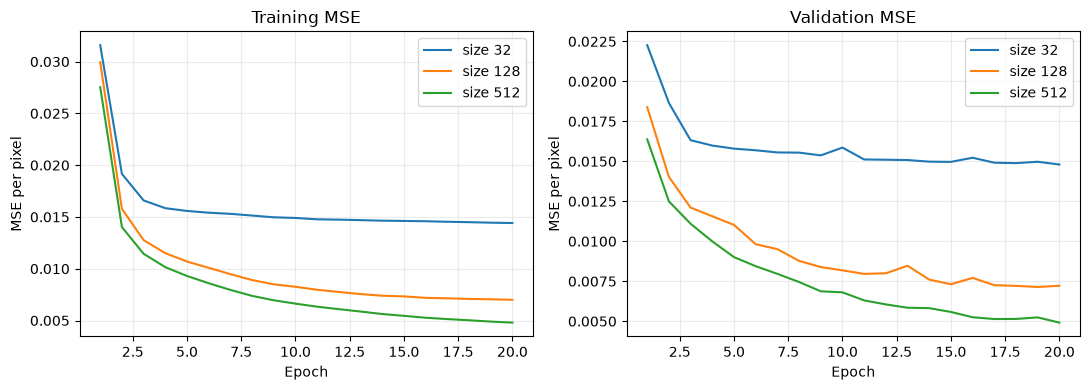

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for size, history in clean_histories.items():
    axes[0].plot(history["epoch"], history["train_mse"], label=f"size {size}")
    axes[1].plot(history["epoch"], history["val_mse"], label=f"size {size}")
for ax, title in zip(axes, ["Training MSE", "Validation MSE"]):
    ax.set_title(title)
    ax.set_xlabel("Epoch")
    ax.set_ylabel("MSE per pixel")
    ax.grid(alpha=0.25)
    ax.legend()
fig.tight_layout()
fig.savefig(RESULTS / "clean_autoencoder_learning_curves.png", dpi=160)
plt.show()

## Q3(b). Train the denoising autoencoder

The model uses the validation-selected bottleneck size. Its checkpoint is selected using validation MSE on noisy inputs and clean targets.

In [8]:
print("Training denoising autoencoder with bottleneck", best_size)
denoising_history = train_autoencoder(best_size, denoising=True)
denoising_model, denoising_checkpoint = load_autoencoder(RESULTS / "denoising_best.pt")
print("Selected denoising epoch:", denoising_checkpoint["epoch"])
print("Denoising validation MSE:", denoising_checkpoint["val_mse"])

Training denoising autoencoder with bottleneck 512
denoising  | epoch  1/20 | train MSE 0.03060 | val MSE 0.01980
denoising  | epoch  2/20 | train MSE 0.01525 | val MSE 0.01365
denoising  | epoch  3/20 | train MSE 0.01246 | val MSE 0.01195
denoising  | epoch  4/20 | train MSE 0.01120 | val MSE 0.01088
denoising  | epoch  5/20 | train MSE 0.01034 | val MSE 0.01010
denoising  | epoch  6/20 | train MSE 0.00971 | val MSE 0.00942
denoising  | epoch  7/20 | train MSE 0.00903 | val MSE 0.00895
denoising  | epoch  8/20 | train MSE 0.00858 | val MSE 0.00860
denoising  | epoch  9/20 | train MSE 0.00822 | val MSE 0.00850
denoising  | epoch 10/20 | train MSE 0.00794 | val MSE 0.00819
denoising  | epoch 11/20 | train MSE 0.00772 | val MSE 0.00771
denoising  | epoch 12/20 | train MSE 0.00750 | val MSE 0.00769
denoising  | epoch 13/20 | train MSE 0.00731 | val MSE 0.00759
denoising  | epoch 14/20 | train MSE 0.00715 | val MSE 0.00723
denoising  | epoch 15/20 | train MSE 0.00699 | val MSE 0.00734
deno

## Q3(c). Class information in the representations

Freeze each clean autoencoder encoder and train a linear classifier on its bottleneck features and the training labels. The encoders are not fine-tuned. The same fixed classifier settings are used for all three representations. We then compare test linear-probe accuracy with test reconstruction MSE.

In [9]:
@torch.no_grad()
def extract_features(model, loader):
    model.eval()
    all_features = []
    all_labels = []
    for clean, _, labels_batch in loader:
        features = model.encode(clean.to(DEVICE))
        all_features.append(features.cpu().numpy())
        all_labels.append(labels_batch.numpy())
    return np.concatenate(all_features), np.concatenate(all_labels)

probes = {}
probe_validation_rows = []
for size in BOTTLENECKS:
    model, _ = load_autoencoder(RESULTS / f"clean_{size}_best.pt")
    for parameter in model.parameters():
        parameter.requires_grad = False
    print("Extracting training features for bottleneck", size, flush=True)
    features_train, labels_train = extract_features(model, train_feature_loader)
    features_val, labels_val = extract_features(model, val_loader)
    # Fixed settings across all encoders: no selection using test data.
    probe = make_pipeline(StandardScaler(),
                          SGDClassifier(loss="log_loss", random_state=SEED,
                                        max_iter=1000, tol=0.001))
    probe.fit(features_train, labels_train)
    probes[size] = probe
    val_accuracy = probe.score(features_val, labels_val)
    probe_validation_rows.append({"Bottleneck size": size, "Validation probe accuracy": val_accuracy})
    joblib.dump(probe, RESULTS / f"linear_probe_{size}.joblib")
    print(f"Bottleneck {size}: validation probe accuracy = {val_accuracy:.4f}")
    del features_train, features_val

probe_validation_table = pd.DataFrame(probe_validation_rows)
probe_validation_table.to_csv(RESULTS / "probe_validation_results.csv", index=False)
display(probe_validation_table)

Extracting training features for bottleneck 32
Bottleneck 32: validation probe accuracy = 0.3236
Extracting training features for bottleneck 128
Bottleneck 128: validation probe accuracy = 0.3636
Extracting training features for bottleneck 512
Bottleneck 512: validation probe accuracy = 0.4146


,Bottleneck size,Validation probe accuracy
0,32,0.3236
1,128,0.3636
2,512,0.4146


## Q3(b). Fixed Q2 classifier

The same Q2 clean-image CNN is used for all inputs. Its weights stay fixed, and inputs are normalized in the same way as in Q2.

In [10]:
class Q2CNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(64, 128, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Flatten(), nn.Linear(128 * 4 * 4, 128), nn.ReLU(), nn.Linear(128, 10)
        )
    def forward(self, x):
        return self.layers(x)

checkpoint = torch.load(cnn_path, map_location=DEVICE, weights_only=False)
assert checkpoint["condition"] == "clean" and checkpoint["model"] == "CNN"
classifier = Q2CNN().to(DEVICE)
classifier.load_state_dict(checkpoint["state_dict"])
classifier.eval()
for parameter in classifier.parameters():
    parameter.requires_grad = False
print("Loaded fixed Q2 CNN from validation-selected epoch:", checkpoint["epoch"])

mean = torch.tensor([0.4914, 0.4822, 0.4465], device=DEVICE).view(1, 3, 1, 1)
std = torch.tensor([0.2470, 0.2435, 0.2616], device=DEVICE).view(1, 3, 1, 1)
def normalize_for_cnn(images):
    return (images - mean) / std

Loaded fixed Q2 CNN from validation-selected epoch: 6


## Q3. Final test evaluation

Report the selected autoencoder's test MSE, compare all three frozen representations, and evaluate the fixed CNN on clean, noisy and reconstructed images.

In [11]:
test_data = datasets.CIFAR10(root=str(DATA_FOLDER), train=False,
                             download=True, transform=transforms.ToTensor())
test_set = ImagePairs(test_data, np.arange(len(test_data)), test_data=True)
test_loader = make_loader(test_set)

# Q3(a) and Q3(c): reconstruction quality on clean test images.
comparison_rows = []
for size in BOTTLENECKS:
    model, _ = load_autoencoder(RESULTS / f"clean_{size}_best.pt")
    mse = reconstruction_mse(model, test_loader, noisy_input=False)
    test_features, test_labels = extract_features(model, test_loader)
    probe_accuracy = probes[size].score(test_features, test_labels)
    comparison_rows.append({"Bottleneck size": size, "Test reconstruction MSE": mse,
                            "Test linear probe accuracy": probe_accuracy,
                            "Selected in Q3(a)": size == best_size})
    del test_features
comparison_table = pd.DataFrame(comparison_rows)
comparison_table.to_csv(RESULTS / "test_reconstruction_and_probe.csv", index=False)
print("Q3(a) and Q3(c):")
display(comparison_table)
print("Selected clean autoencoder test MSE:",
      comparison_table.loc[comparison_table["Selected in Q3(a)"], "Test reconstruction MSE"].iloc[0])

# Q3(b): all four inputs are evaluated with the same frozen CNN and same noisy images.
@torch.no_grad()
def compare_classifier_inputs(loader):
    classifier.eval()
    clean_model.eval()
    denoising_model.eval()
    correct = {"Clean images": 0, "Noisy images": 0,
               "Clean autoencoder on noisy images": 0,
               "Denoising autoencoder on noisy images": 0}
    total = 0
    for clean, noisy, labels_batch in loader:
        clean, noisy = clean.to(DEVICE), noisy.to(DEVICE)
        labels_batch = labels_batch.to(DEVICE)
        image_versions = {
            "Clean images": clean,
            "Noisy images": noisy,
            "Clean autoencoder on noisy images": clean_model(noisy),
            "Denoising autoencoder on noisy images": denoising_model(noisy)
        }
        for name, images in image_versions.items():
            predictions = classifier(normalize_for_cnn(images)).argmax(dim=1)
            correct[name] += (predictions == labels_batch).sum().item()
        total += labels_batch.size(0)
    return pd.DataFrame([{"Input to fixed Q2 CNN": name, "Test accuracy": count / total,
                          "Test error rate": 1 - count / total} for name, count in correct.items()])

cnn_results = compare_classifier_inputs(test_loader)
cnn_results.to_csv(RESULTS / "denoising_classifier_test_results.csv", index=False)
print("Q3(b):")
display(cnn_results)

Q3(a) and Q3(c):


,Bottleneck size,Test reconstruction MSE,Test linear probe accuracy,Selected in Q3(a)
0,32,0.014503,0.3203,False
1,128,0.006987,0.3546,False
2,512,0.004800,0.4168,True


Selected clean autoencoder test MSE: 0.004800274352232615
Q3(b):


,Input to fixed Q2 CNN,Test accuracy,Test error rate
0,Clean images,0.7490,0.2510
1,Noisy images,0.2507,0.7493
2,Clean autoencoder on noisy images,0.4651,0.5349
3,Denoising autoencoder on noisy images,0.4602,0.5398


## Q3(a). Answer: reconstruction

The selected 512-dimensional autoencoder obtained **0.004800 test MSE**. Its validation MSE was lower than the 32- and 128-dimensional models, so it is the appropriate choice when reconstruction error is the only criterion.

## Q3(b). Answer: does denoising help the classifier?

| Input to the same fixed Q2 CNN | Test accuracy |
|---|---:|
| Clean images | 74.90% |
| Noisy images | 25.07% |
| Clean autoencoder applied to noisy images | 46.51% |
| Denoising autoencoder applied to noisy images | 46.02% |

The denoising output improved accuracy by **20.95 percentage points** over the noisy input, so it recovered some information useful to this CNN. It remained **28.88 points** below clean-image accuracy and was **0.49 points below** the clean-autoencoder baseline. Therefore, this run supports a benefit over raw noisy images, but does not show an improvement over the clean autoencoder. The reconstructions look smoother but lose fine detail.

## Q3(c). Answer: reconstruction versus class information

| Bottleneck | Test reconstruction MSE | Test linear-probe accuracy |
|---:|---:|---:|
| 32 | 0.014503 | 32.03% |
| 128 | 0.006987 | 35.46% |
| 512 | 0.004800 | 41.68% |

In this experiment, larger bottlenecks achieved both lower reconstruction error and higher linear-probe accuracy, so the rankings agree. This does not prove that reconstruction and class information always agree: MSE measures pixel reconstruction, while a linear probe measures class information that is linearly accessible.

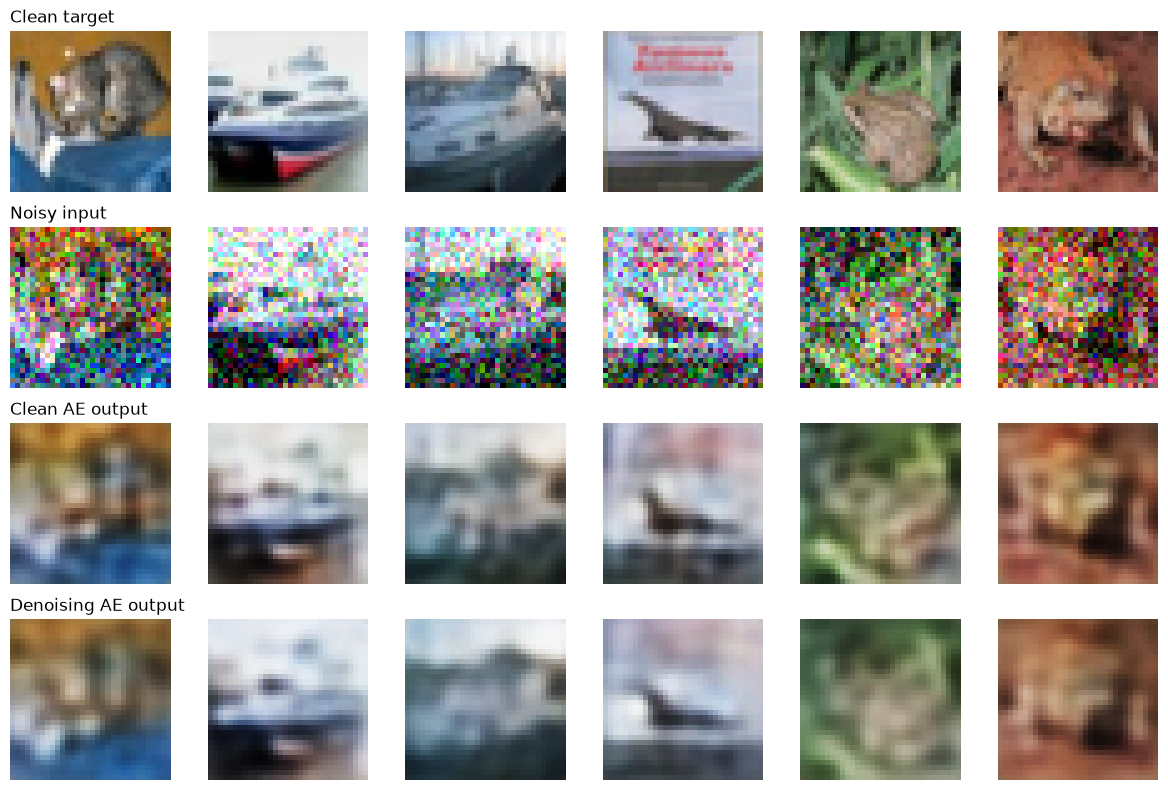

In [12]:
# Visualize test reconstructions after the experiment choices are fixed.
clean_batch, noisy_batch, labels_batch = next(iter(test_loader))
with torch.no_grad():
    baseline = clean_model(noisy_batch.to(DEVICE)).cpu()
    denoised = denoising_model(noisy_batch.to(DEVICE)).cpu()
images = [clean_batch, noisy_batch, baseline, denoised]
titles = ["Clean target", "Noisy input", "Clean AE output", "Denoising AE output"]
fig, axes = plt.subplots(4, 6, figsize=(12, 8))
for row in range(4):
    for col in range(6):
        axes[row, col].imshow(images[row][col].permute(1, 2, 0).clamp(0, 1))
        axes[row, col].axis("off")
        if col == 0:
            axes[row, col].set_ylabel(titles[row])
    axes[row, 0].set_title(titles[row], loc="left")
fig.tight_layout()
fig.savefig(RESULTS / "test_reconstruction_examples.png", dpi=160, bbox_inches="tight")
plt.show()